In [1]:
from datasets import load_dataset

dataset = load_dataset("sezenkarakus/image-description-dataset-v2")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/361 [00:00<?, ?B/s]

data/train-00000-of-00014.parquet:   0%|          | 0.00/511M [00:00<?, ?B/s]

data/train-00001-of-00014.parquet:   0%|          | 0.00/485M [00:00<?, ?B/s]

data/train-00002-of-00014.parquet:   0%|          | 0.00/478M [00:00<?, ?B/s]

...

data/train-00010-of-00014.parquet:   0%|          | 0.00/479M [00:00<?, ?B/s]

data/train-00011-of-00014.parquet:   0%|          | 0.00/475M [00:00<?, ?B/s]

data/train-00012-of-00014.parquet:   0%|          | 0.00/486M [00:00<?, ?B/s]

data/train-00013-of-00014.parquet:   0%|          | 0.00/476M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/19610 [00:00<?, ? examples/s]

In [2]:
dataset = dataset['train']

In [3]:
print(dataset)
print(dataset.column_names)
print(len(dataset['file_name']))

Dataset({
    features: ['file_name', 'text', 'image'],
    num_rows: 19610
})
['file_name', 'text', 'image']
19610


<class 'PIL.PngImagePlugin.PngImageFile'>
(408, 612)
<class 'PIL.PngImagePlugin.PngImageFile'>
(612, 408)


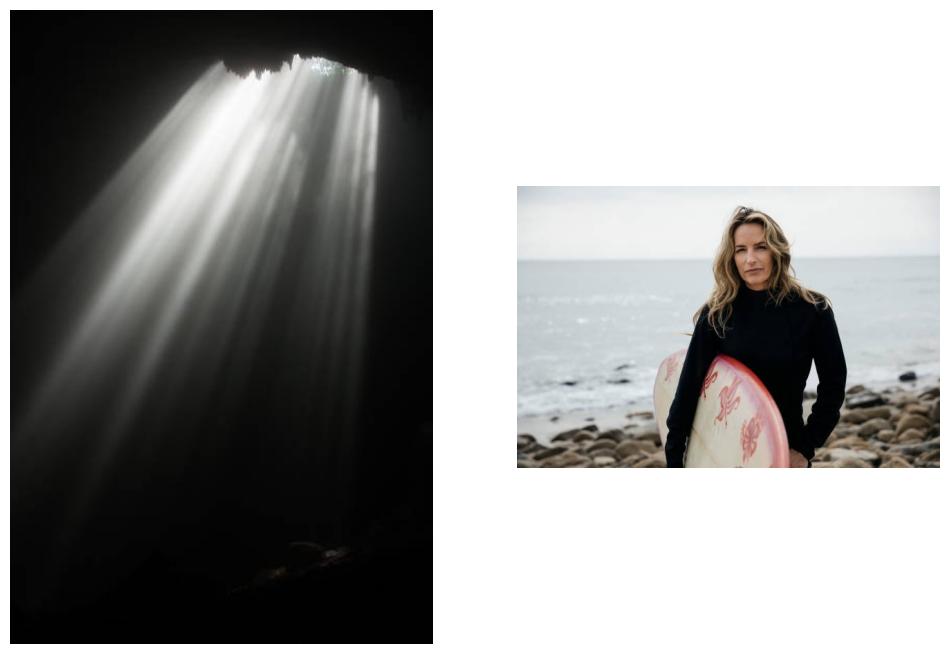

In [ ]:
import matplotlib.pyplot as plt
sample = dataset.shuffle(seed=1234).select(range(3))

plt.figure(figsize=(12,12))
img = sample['image'][1]
print(type(img))          # check type
print(img.size)
plt.subplot(1,2,1)
plt.imshow(img)
plt.axis('off')
img = sample['image'][2]
print(type(img))          # check type
print(img.size)
plt.subplot(1,2,2)
plt.imshow(img)
plt.axis('off')
plt.show()

In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
])
def process_image(example):
    example['image_transformed'] = transform(example['image'])
    return example

dataset = dataset.map(process_image)

Map:   0%|          | 0/19610 [00:00<?, ? examples/s]

In [ ]:
dataset.set_format(type='torch', columns=['image_transformed'])

<class 'torch.Tensor'>
<built-in method size of Tensor object at 0x78919c55e670>
<class 'torch.Tensor'>
<built-in method size of Tensor object at 0x78919c2f7e30>


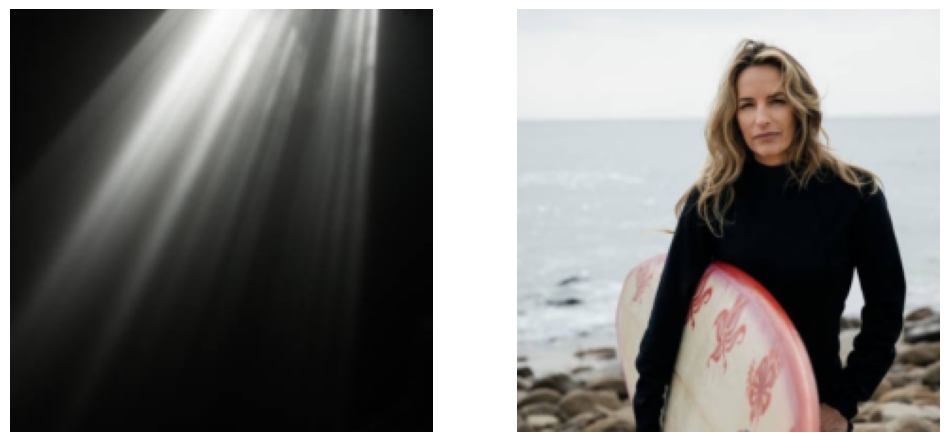

In [ ]:
import matplotlib.pyplot as plt
sample = dataset.shuffle(seed=1234).select(range(3))

plt.figure(figsize=(12,12))
img = sample['image_transformed'][1]
print(type(img))          # check type
print(img.size)
# (C,H,W) → (H,W,C)
img = img.permute(1, 2, 0)
plt.subplot(1,2,1)
plt.imshow(img)
plt.axis('off')
img = sample['image_transformed'][2]
print(type(img))          # check type
print(img.size)
img = img.permute(1, 2, 0)
plt.subplot(1,2,2)
plt.imshow(img)
plt.axis('off')
plt.show()


In [ ]:
# dataset.save_to_disk("/content/drive/MyDrive/my_dataset")
dataset.save_to_disk("/my_dataset")

Saving the dataset (0/38 shards):   0%|          | 0/19610 [00:00<?, ? examples/s]

In [ ]:
import shutil

shutil.move("/my_dataset", "/content/my_dataset")

'/content/my_dataset'

In [ ]:
# Step 1: Zip the dataset folder
!zip -r my_dataset.zip /content/my_dataset

# Step 2: Download to your computer
from google.colab import files
files.download("my_dataset.zip")

  adding: content/my_dataset/ (stored 0%)
  adding: content/my_dataset/data-00030-of-00038.arrow (deflated 50%)
  adding: content/my_dataset/data-00018-of-00038.arrow (deflated 48%)
  adding: content/my_dataset/data-00029-of-00038.arrow (deflated 49%)
  adding: content/my_dataset/data-00032-of-00038.arrow (deflated 48%)
  adding: content/my_dataset/data-00001-of-00038.arrow (deflated 47%)
  adding: content/my_dataset/data-00031-of-00038.arrow (deflated 48%)
  adding: content/my_dataset/data-00025-of-00038.arrow (deflated 49%)
  adding: content/my_dataset/data-00003-of-00038.arrow (deflated 48%)
  adding: content/my_dataset/data-00007-of-00038.arrow (deflated 49%)
  adding: content/my_dataset/data-00027-of-00038.arrow (deflated 48%)
  adding: content/my_dataset/data-00021-of-00038.arrow (deflated 47%)
  adding: content/my_dataset/data-00028-of-00038.arrow (deflated 49%)
  adding: content/my_dataset/data-00008-of-00038.arrow (deflated 49%)
  adding: content/my_dataset/data-00034-of-00038

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

shutil.move("/content/my_dataset", "/content/drive/MyDrive/MediaMark")

'/content/drive/MyDrive/MediaMark/my_dataset'